# 01 — Data and train/test split

Cleaning, features and the split (code: `src/data.py`).

In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')
import pandas as pd
pd.set_option('display.precision', 3)
from src.data import load_all, to_3_classes, CLASS_NAMES, LEAKY_COLUMNS
from src import plots

df = load_all()
df['target'] = pd.Categorical.from_codes(to_3_classes(df['Severity'].to_numpy()), CLASS_NAMES)
print(df.shape)
print('Excluded columns:', LEAKY_COLUMNS)

(1741433, 42)
Excluded columns: ['End_Time', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description']


## Drift

The share of severe accidents depends on the data source and changes over the years.

In [2]:
pd.crosstab(df['Source'], df['target'], normalize='index').mul(100).round(1)

target,Sev1-2,Sev3,Sev4
Source,,,
Source1,97.0,1.9,1.1
Source2,60.0,39.8,0.1
Source3,65.3,34.6,0.1


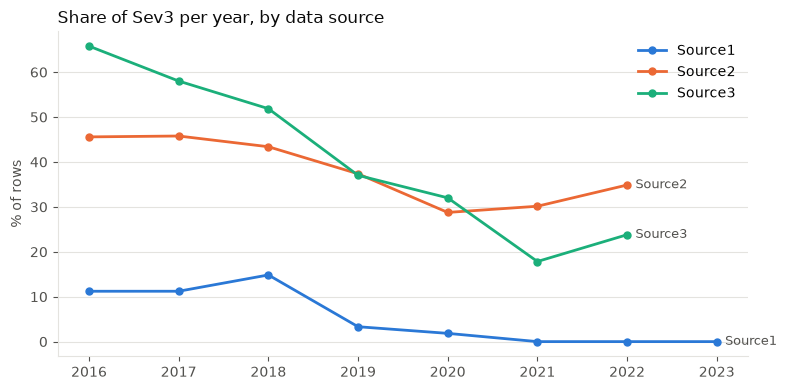

In [3]:
fig = plots.share_by_year(df, 'target', 'Sev3', title='Share of Sev3 per year, by data source')

In [4]:
pd.crosstab(df['Year'], df['Source'])

Source,Source1,Source2,Source3
Year,,,
2016,34465,105949,38
2017,35970,113994,2784
2018,35415,116464,5019
2019,108408,89704,15343
2020,211062,57450,17020
2021,265286,70994,5596
2022,338937,32312,4664
2023,74559,0,0


## Train/test split

`test_out` (2022–2023) has a very different mix of classes and sources than the training data.

In [5]:
summary = pd.crosstab(df['split'], df['target'], normalize='index').mul(100).round(2)
summary['rows'] = df['split'].value_counts()
summary['% Source1'] = (df['Source'] == 'Source1').groupby(df['split']).mean().mul(100).round(1)
summary

target,Sev1-2,Sev3,Sev4,rows,% Source1
split,,,,,
test_in,79.11,20.10,0.79,193503,53.5
test_out,96.51,2.75,0.75,450472,91.8
train,79.12,20.10,0.79,1097458,53.5


In [6]:
# Check: no event (duplicate records of the same accident) appears in two parts of the split
print('max number of parts per event:', df.groupby('event_id')['split'].nunique().max())

max number of parts per event: 1
